In [1]:
import os

import cartopy.crs as ccrs
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from vke_budgets import budget, io, pipeline
from vke_budgets.sources import merra2

MERRA2_ROOT = "/scratch/groups/dayang/Aidi/VKE_budget/data"
OUT = "/scratch/users/yucli/vke-budgets/july2017"

BOX = {"lon": (190.0, 240.0), "lat": (25.0, 55.0)} # 170-120 W, 25-55 N
FIGURES = os.path.join(OUT, "figures")
os.makedirs(FIGURES, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIGURES, name), dpi=200, bbox_inches="tight")
    
def region(da, bounds):
    da = da.assign_coords(lon=da["lon"] % 360).sortby("lon")
    return da.sel(lon=slice(*bounds["lon"]), lat=slice(*bounds["lat"]))


def area_integral(da):
    """Integral over the latitude-longitude domain of da, weighted by cos(lat)."""
    return (da * np.cos(np.deg2rad(da["lat"]))).sum(("lat", "lon"))


def area_rms(da):
    weights = np.cos(np.deg2rad(da["lat"])) * xr.ones_like(da)
    return float(np.sqrt(area_integral(da**2).sum() / area_integral(weights).sum()))


In [2]:
options = budget.BudgetOptions(quantities=("KEV",), dyn_crosscheck=True)
pipeline.run("2017-07-12", "2017-07-12", MERRA2_ROOT, OUT, options, n_workers=3)
ds = io.open_budget(os.path.join(OUT, "budget_*.nc")).load()
g = budget.groups(ds, "KEV")

model_dynamics = ds["kev_model_dynamics_momentum"] + ds["kev_model_dynamics_vapor"]
physics = g["subgrid_momentum"] + g["net_vapor_source"] + g["analysis"]


resid1 = g["tend"] - sum([g[k] for k in [
    "hflux", "vflux", "pe_conversion", "subgrid_momentum", "net_vapor_source", "analysis"
]])

resid2 = g["tend"] - sum(ds[k] for k in [
    "kev_hflux_ke", "kev_hflux_vapor", "kev_vflux_ke", "kev_vflux_vapor", "kev_pe_conversion" 
]) - physics

# note: resid1 and resid2 should be close to float32 precision
# resid1 and resid2 should be different than g["residual"] by the boundary term

residuals = {
    "IKEVTEND - (IDOKE + IDOV) - physics": g["tend"] - model_dynamics - physics,
    "IKEVTEND - (IHAKE + IHCV + IVAKE + IVCV + IPEKE) - physics": resid2,
}
tend = g["tend"]

budget_20170712-20170712.nc exists, skipped


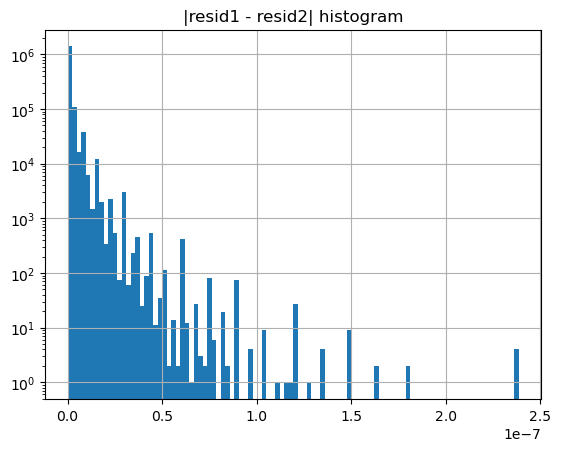

In [4]:
plt.hist(np.abs(resid1 - resid2).values.flatten(), bins=100, log=True)
plt.title("|resid1 - resid2| histogram")
plt.grid()
plt.show()

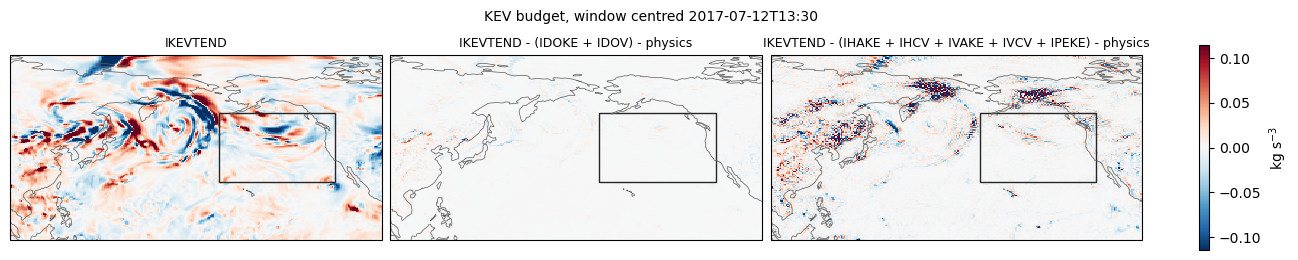

In [17]:
MAP = {"lon": (100.0, 260.0), "lat": (0.0, 80.0)}

def maps(fields, title, cmap, vmin, vmax, units="kg s$^{-3}$"):
    fig, axes = plt.subplots(1, len(fields), figsize=(4.3 * len(fields), 2.6), squeeze=False,
                             layout="constrained",
                             subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
    for ax, (name, f) in zip(axes.flat, fields.items()):
        f = region(f, MAP)
        mesh = ax.pcolormesh(f["lon"], f["lat"], f, cmap=cmap, vmin=vmin, vmax=vmax,
                             transform=ccrs.PlateCarree(), shading="auto")
        ax.coastlines(linewidth=0.5, color="0.35")
        ax.add_patch(mpatches.Rectangle((BOX["lon"][0], BOX["lat"][0]), np.diff(BOX["lon"])[0],
                                        np.diff(BOX["lat"])[0], fill=False, edgecolor="0.15",
                                        linewidth=1.0, transform=ccrs.PlateCarree()))
        ax.set_extent([*MAP["lon"], *MAP["lat"]], crs=ccrs.PlateCarree())
        ax.set_title(name, fontsize=9)
    fig.colorbar(mesh, ax=axes, shrink=0.9, label=units)
    fig.suptitle(title, fontsize=10)
    return fig


frame = 4
fields_to_plot = {
    "IKEVTEND": tend.isel(time=frame), 
    **{n: r.isel(time=frame) for n, r in residuals.items()}
}
vmax = float(np.nanpercentile(np.abs(region(fields_to_plot["IKEVTEND"], MAP)), 98))
fig = maps(fields_to_plot, f"KEV budget, window centred {str(ds['time'].values[frame])[:16]}", "RdBu_r", -vmax, vmax)
save(fig, "kev_tend_residual.png")

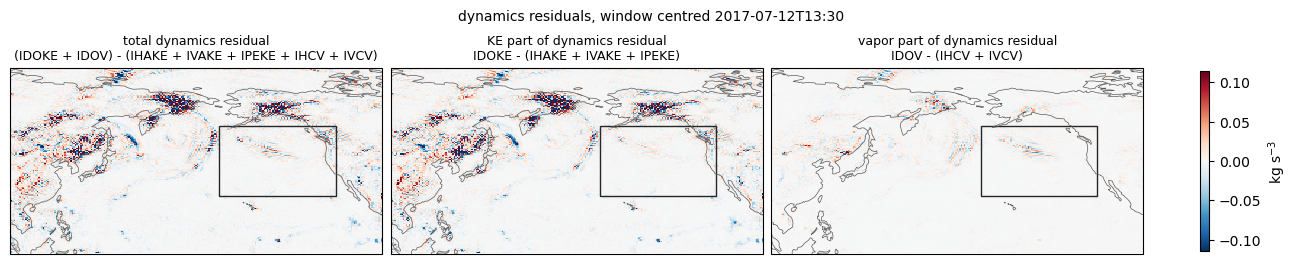

In [27]:
ke_dyn_resid = ds["kev_model_dynamics_momentum"] - (ds["kev_hflux_ke"] + ds["kev_vflux_ke"] + ds["kev_pe_conversion"])
vapor_dyn_resid = ds["kev_model_dynamics_vapor"] - (ds["kev_hflux_vapor"] + ds["kev_vflux_vapor"])

fields_to_plot = {
    "total dynamics residual\n(IDOKE + IDOV) - (IHAKE + IVAKE + IPEKE + IHCV + IVCV)": (ke_dyn_resid + vapor_dyn_resid).isel(time=frame),
    "KE part of dynamics residual\nIDOKE - (IHAKE + IVAKE + IPEKE)": ke_dyn_resid.isel(time=frame),
    "vapor part of dynamics residual\nIDOV - (IHCV + IVCV)": vapor_dyn_resid.isel(time=frame),
}
fig = maps(fields_to_plot, f"dynamics residuals, window centred {str(ds['time'].values[frame])[:16]}", "RdBu_r", -vmax, vmax)
save(fig, "kev_tend_residual_dynamics_isolated.png")